# Surface Temperature Maps of Rocky Exoplanets

How warm are the nearest potentially habitable exoplanets, and could any of their surface hold liquid water? This notebook walks through the `exotemp.py` model. The model has three parameters:

* **Bond albedo** $A$, the fraction of starlight reflected,
* **heat-redistribution efficiency** $\varepsilon$, from 0 (no heat transport, a "bare rock") to 1 (temperature equal everywhere),
* **greenhouse absorptivity** $g$ of a single-layer grey atmosphere, from 0 (airless) to 1 (opaque in the infrared).

In [1]:
import numpy as np
import pandas as pd
from IPython.display import Image
import exotemp as et

pd.set_option("display.float_format", "{:.3g}".format)

## 1. Check the model on Earth

$T_{\rm eq} = \left[\dfrac{S(1-A)}{4\sigma}\right]^{1/4}$, and a single-layer atmosphere warms the surface by a factor $\left(\dfrac{2}{2-g}\right)^{1/4}$.

In [2]:
t_eq = et.equilibrium_temperature(et.SOLAR_CONSTANT, albedo=0.3)
print(f"Earth equilibrium temperature: {t_eq:.1f} K")
print(f"Earth surface temperature (g = 0.78): {et.surface_temperature(t_eq, 0.78):.1f} K   (observed mean ~288 K)")

Earth equilibrium temperature: 254.6 K
Earth surface temperature (g = 0.78): 288.1 K   (observed mean ~288 K)


## 2. The planets

Insolation is computed from the stellar luminosity and orbital distance in `data/planets.csv`, which lists the source of each value. All the exoplanets here orbit M dwarfs so closely that they are expected to be **tidally locked**: one hemisphere always faces the star.

In [3]:
planets = et.load_planets()
planets[["planet", "star", "semi_major_axis_au", "flux_searth", "flux_w_m2", "reference"]]

,planet,star,semi_major_axis_au,flux_searth,flux_w_m2,reference
0,Earth,Sun,1,1,1.36e+03,NaN
1,Proxima Cen b,Proxima Centauri,0.0485,0.659,897,Anglada-Escudé et al. 2016
2,Proxima Cen d,Proxima Centauri,0.0289,1.86,2.53e+03,Faria et al. 2022
3,TRAPPIST-1 d,TRAPPIST-1,0.0223,1.12,1.52e+03,Agol et al. 2021
4,TRAPPIST-1 e,TRAPPIST-1,0.0293,0.646,880,Agol et al. 2021
5,TRAPPIST-1 f,TRAPPIST-1,0.0385,0.373,508,Agol et al. 2021
6,TOI-700 d,TOI-700,0.163,0.877,1.19e+03,Gilbert et al. 2020
7,Teegarden's Star b,Teegarden's Star,0.0252,1.15,1.56e+03,Zechmeister et al. 2019
8,Teegarden's Star c,Teegarden's Star,0.0443,0.372,506,Zechmeister et al. 2019


## 3. Summary temperatures (A = 0.3, g = 0.78)

* `T_day_bare_rock_K`: dayside brightness temperature with no heat transport and no atmosphere.
* `T_substellar_eps0.3_K`: temperature at the point directly below the star with moderate heat transport.
* `water_fraction_eps0.3`: fraction of the surface between 273 and 373 K.

In [4]:
et.summary_table(planets, albedo=0.3, g=0.78)

,planet,insolation_searth,T_eq_K,T_surface_global_K,T_day_bare_rock_K,T_substellar_eps0.3_K,water_fraction_eps0.3
0,Earth,1,255,288,NaN,NaN,NaN
1,Proxima Cen b,0.659,229,260,293,344,0.333
2,Proxima Cen d,1.86,297,337,380,446,0.193
3,TRAPPIST-1 d,1.12,262,296,334,393,0.322
4,TRAPPIST-1 e,0.646,228,258,292,343,0.33
5,TRAPPIST-1 f,0.373,199,225,254,299,0.167
6,TOI-700 d,0.877,246,279,315,370,0.389
7,Teegarden's Star b,1.15,264,298,337,396,0.312
8,Teegarden's Star c,0.372,199,225,254,298,0.166


## 4. Dayside temperature across albedo and heat transport

Following Cowan & Agol (2011), $T_{\rm day}^4 = \dfrac{S}{\sigma}(1-A)\left(\dfrac{2}{3} - \dfrac{5\varepsilon}{12}\right)$. The blue line marks 273 K and the white line 373 K.

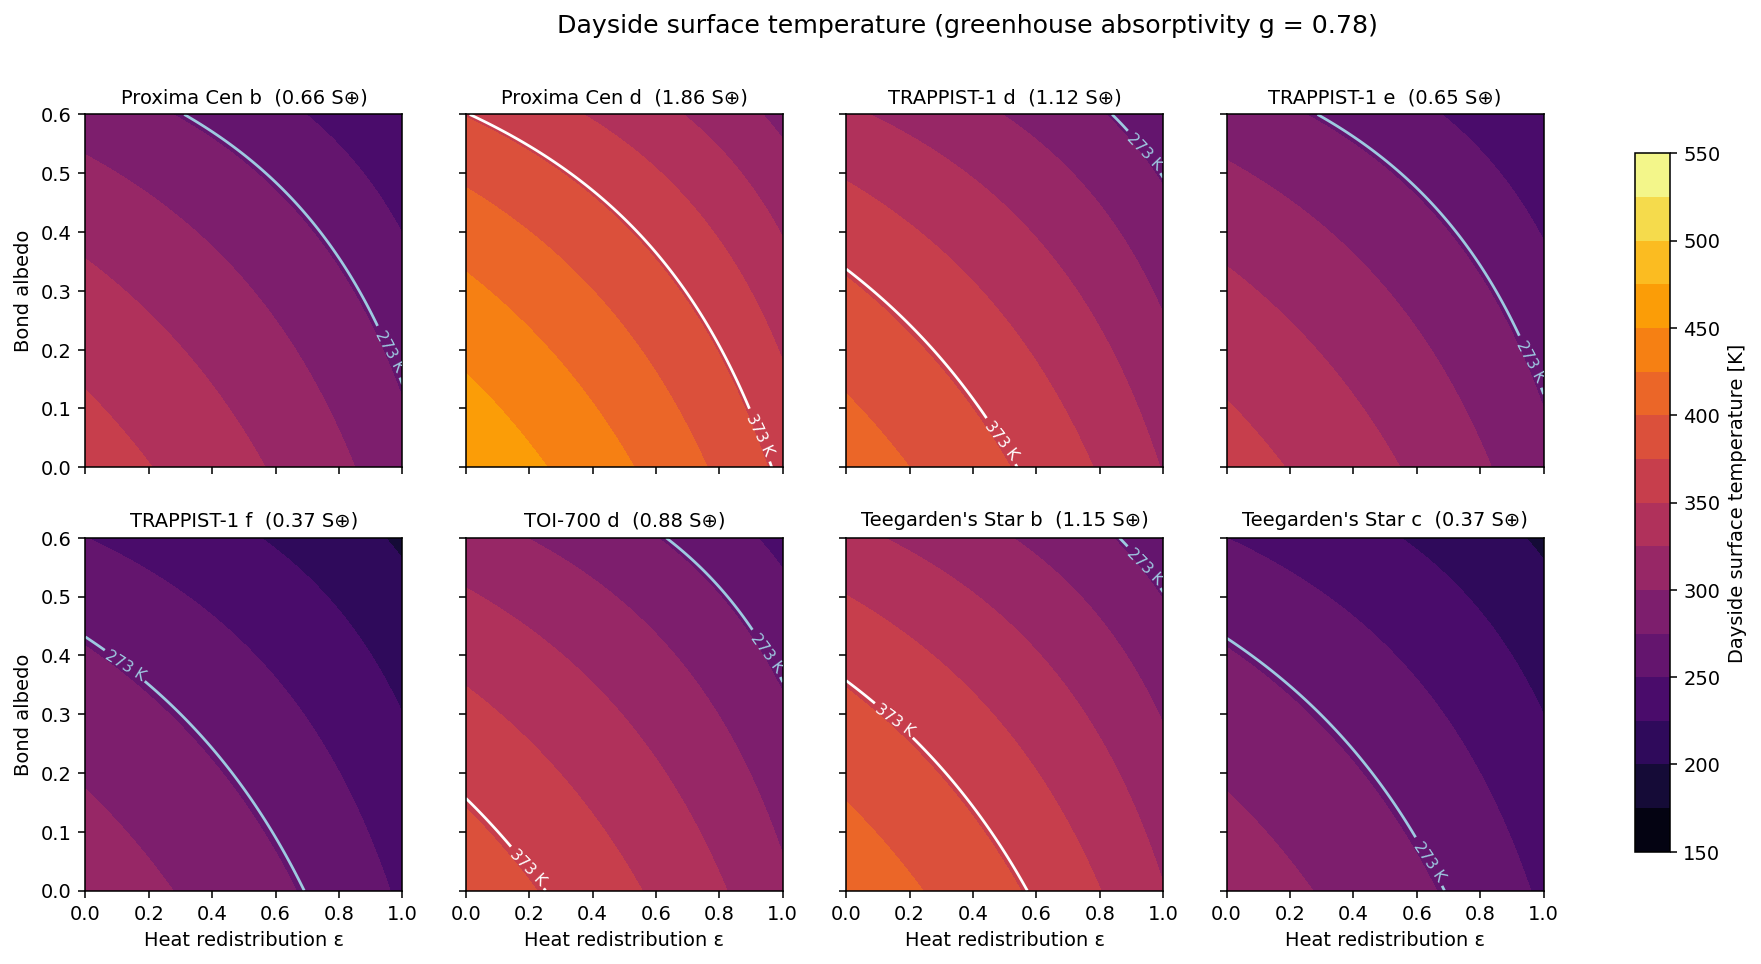

In [5]:
et.plot_parameter_maps(planets, "figures/dayside_parameter_maps.png", g=0.78)
Image("figures/dayside_parameter_maps.png", width=950)

## 5. Surface temperature maps: "eyeball" worlds

Each point re-radiates the fraction $1-\varepsilon$ of the starlight it receives locally, and the fraction $\varepsilon$ is spread evenly over the planet:

$$\sigma T^4(\phi,\lambda) = S(1-A)\left[(1-\varepsilon)\max(\cos Z, 0) + \frac{\varepsilon}{4}\right].$$

With little heat transport, a temperate patch faces the star while the nightside freezes. With full heat transport, Proxima b is uniformly below freezing.

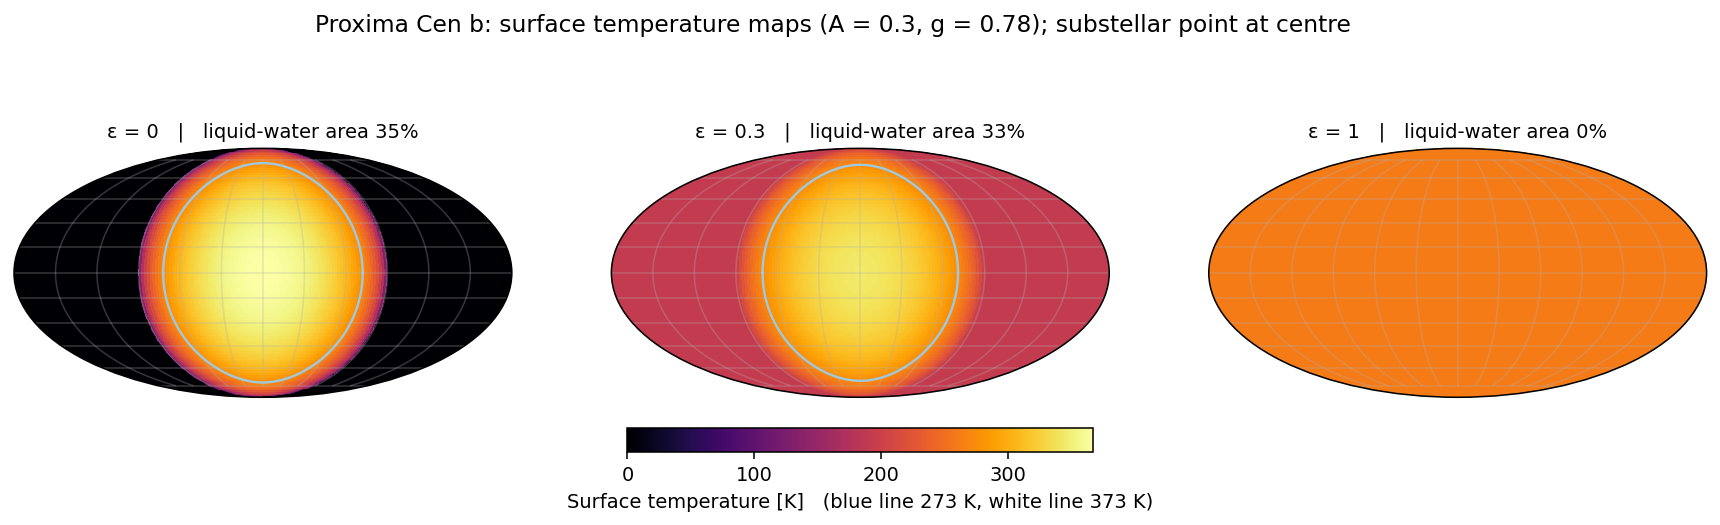

In [6]:
proxb = planets[planets.planet == "Proxima Cen b"].iloc[0]
et.plot_surface_maps(proxb, "figures/surface_maps.png", albedo=0.3, g=0.78)
Image("figures/surface_maps.png", width=950)

## 6. How much of the surface could hold liquid water?

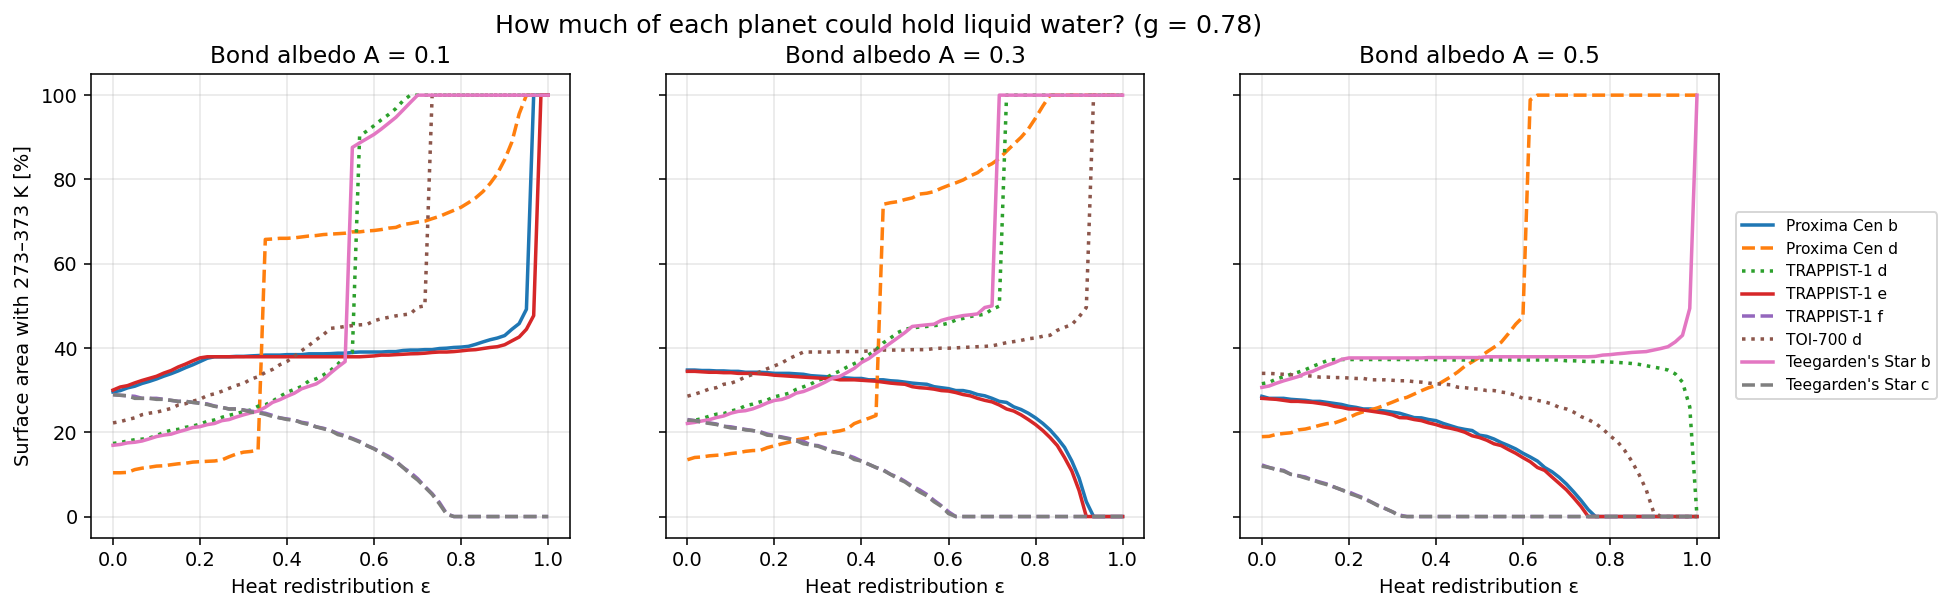

In [7]:
et.plot_water_fraction(planets, "figures/liquid_water_fraction.png", g=0.78)
Image("figures/liquid_water_fraction.png", width=950)

Heat transport matters as much as the amount of starlight. Proxima b and TRAPPIST-1 e keep a temperate patch of about a third of their surface when heat transport is weak, but freeze over completely when it is efficient. Warmer planets such as TRAPPIST-1 d and Teegarden's Star b become entirely temperate when heat is spread evenly.

## 7. Observable signature: thermal phase curves

Heat transport is measurable: a planet with weak redistribution is bright at secondary eclipse and dark at transit. This is how JWST constrains the atmospheres of the TRAPPIST-1 planets.

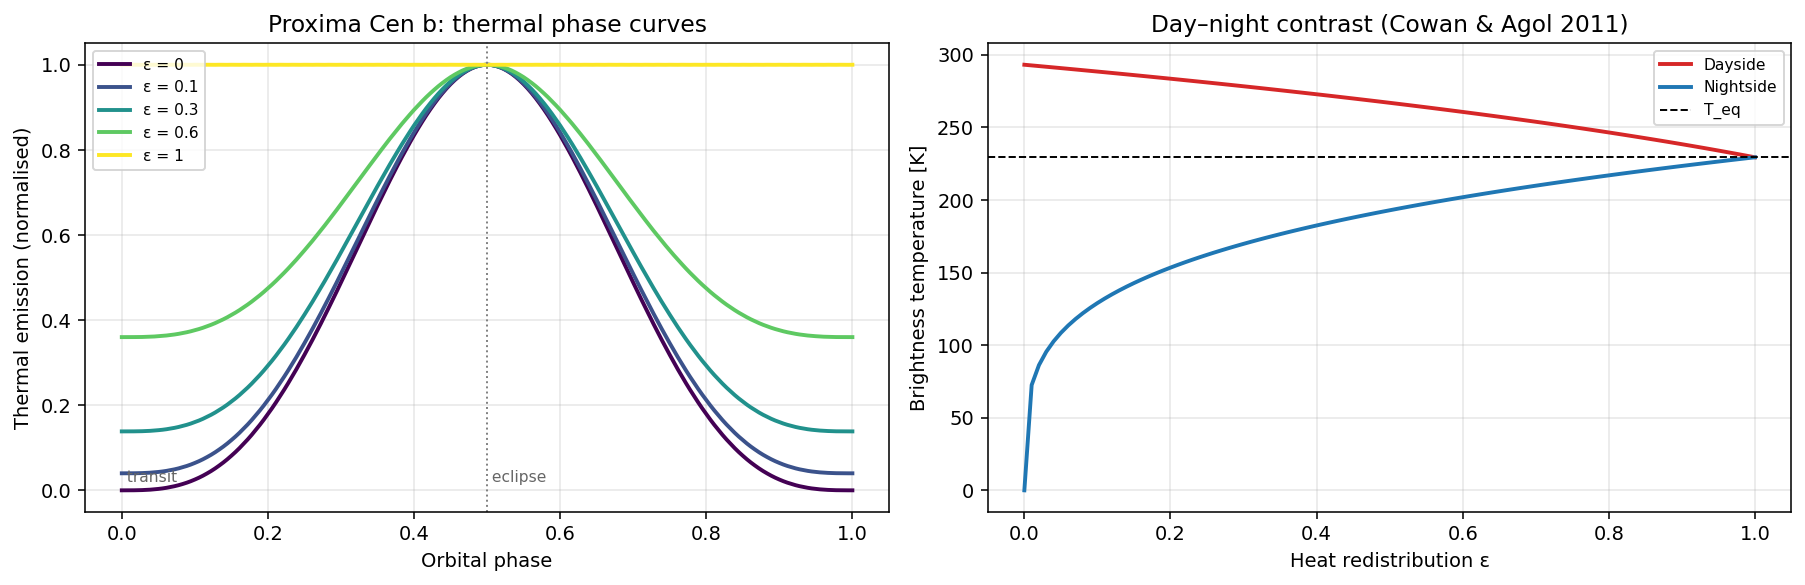

In [8]:
et.plot_phase_curves(proxb, "figures/phase_curves.png", albedo=0.3)
Image("figures/phase_curves.png", width=950)

## Limitations

These are energy-balance estimates, not climate simulations. They leave out ocean and atmospheric dynamics, clouds, ice–albedo feedback, the spectral energy distribution of M dwarfs (which changes the effective albedo), and atmospheric loss driven by stellar activity. The same grey greenhouse strength is applied everywhere on the surface.